В этом домашнем задании мы продолжим работу над детектором из семинара, поэтому при необходимости можете заимствовать оттуда любой код.

Домашнее задание можно разделить на следующие части:

* Переделываем модель [4]
  * Backbone[1],
  * Neck [2],
  * Head [1]
* Label assignment [3]:
  * TAL [3]
* Лоссы [1]:
  * CIoU loss [1]
* Кто больше? [5]
  * 0.05 mAP [1]
  * 0.1 mAP  [2]
  * 0.2 mAP [5]

**Максимальный балл:** 10 баллов. (+3 балла бонус).

In [1]:
import torch
import numpy as np
import pandas as pd
import albumentations as A

from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset
from albumentations.pytorch.transforms import ToTensorV2

In [2]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda")

print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Seed: {SEED}")

GPU: Tesla T4
Seed: 42


### Загрузка данных

Мы продолжаем работу с датасетом из семинара - Halo infinite ([сслыка](https://universe.roboflow.com/graham-doerksen/halo-infinite-angel-aim)). Загрузка данных и создание датасета полностью скопированы из семинара.

Сначала загружаем данные

In [3]:
splits = {
    "train": "data/train-00000-of-00001-0d6632d599c29801.parquet",
    "validation": "data/validation-00000-of-00001-c6b77a557eeedd52.parquet",
    "test": "data/test-00000-of-00001-866d29d8989ea915.parquet"
}

base_url = "hf://datasets/Francesco/halo-infinite-angel-videogame/"

df_train = pd.read_parquet(base_url + splits["train"])
df_val = pd.read_parquet(base_url + splits["validation"])
df_test = pd.read_parquet(base_url + splits["test"])

print(f"Train: {len(df_train)} | Validation: {len(df_val)} | Test: {len(df_test)}")

Train: 462 | Validation: 71 | Test: 136


Создаем датасет для предобработки данных

In [4]:
import io

class HaloDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        dataframe = dataframe.reset_index(drop=True)
        df_objects = pd.json_normalize(dataframe['objects'])[["bbox", "category"]]
        df_images = pd.json_normalize(dataframe['image'])[["bytes"]]
        self.data = dataframe[["image_id"]].join(df_objects).join(df_images)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        image = Image.open(io.BytesIO(row["bytes"])).convert("RGB")
        image = np.array(image)

        target = {"image_id": row["image_id"]}

        labels = [row["category"]] if isinstance(row["category"], int) else row["category"]
        labels = [label - 1 for label in labels]
        boxes = row["bbox"].tolist()

        if self.transform is not None:
            transformed = self.transform(image=image, bboxes=boxes, labels=labels)
            image, boxes, labels = transformed["image"], transformed["bboxes"], transformed["labels"]
        else:
            image = transforms.ToTensor()(image)

        target["boxes"] = torch.tensor(np.array(boxes), dtype=torch.float32).reshape(-1, 4)
        target["labels"] = torch.tensor(labels, dtype=torch.int64)

        return image, target


def collate_fn(batch):
    batch = tuple(zip(*batch))
    images = torch.stack(batch[0])
    return images, batch[1]

Чтобы модель не переобучалась, можно добавить больше аугментаций, весь список можно посмотреть тут [[ссылка](https://explore.albumentations.ai/)].

Какие можно использовать аугментации?
* Добавить зум `RandomResizedCrop`,
* Сделать цветовые аугментации типа `RandomBrightnessContrast` и/или `HueSaturationValue`,
* Добавить шум `GaussNoise`,
* Вырезать случайные части изображения `CoarseDropout`,
* И любые другие!

Аугментации можно комбинировать посредствам `A.OneOf`, `A.SomeOf` или `A.RandomOrder`.

Хоть аугментации ограничиваются только вашей фантазией, перед обучением советуем посмотреть на результат преобразований и убедиться, что изображение ещё поддается детекции:)

In [5]:
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

train_transform = A.Compose(
    [
        A.Resize(height=640, width=640),
        A.HorizontalFlip(p=0.5),
        A.RandomBrightnessContrast(p=0.3),
        A.HueSaturationValue(p=0.2),
        A.GaussNoise(p=0.1),
        A.Normalize(mean=mean, std=std),
        ToTensorV2(),
    ],
    bbox_params=A.BboxParams(format='coco', label_fields=['labels']),
    seed=SEED
)

test_transform = A.Compose(
    [
        A.Resize(height=640, width=640),
        A.Normalize(mean=mean, std=std),
        ToTensorV2(),
    ],
    bbox_params=A.BboxParams(format='coco', label_fields=['labels'])
)

/usr/local/lib/python3.13/dist-packages/albumentations/core/composition.py:331: UserWarning: Got processor for bboxes, but no transform to process it.
  self._set_keys()


Не забываем инициализировать наш датасет

In [6]:
train_dataset = HaloDataset(df_train, transform=train_transform)
val_dataset = HaloDataset(df_val, transform=test_transform)
test_dataset = HaloDataset(df_test, transform=test_transform)

## Переделываем модель [4 балла]

В семинаре мы реализовали самый базовый детектор, а сейчас настало время его улучшать.

### Backbone [1 балл]

Хорошей практикой считается размораживать несколько последних слоев в backbone, это позволяет немного улучить качество модели. Давайте улушчим класс Backbone из лекции, добавив ему возможность разморозки __k__ последних слоев или блоков (на ваш выбор).

In [7]:
import torch.nn as nn
import timm


class Backbone(nn.Module):
    def __init__(
        self,
        model_name="efficientnet_b0",
        out_indices=(-1, -2, -3),
        unfreeze_last=2
    ):
        super().__init__()

        self.backbone = timm.create_model(
            model_name,
            pretrained=True,
            features_only=True,
            out_indices=out_indices
        )

        # Замораживаем весь backbone
        for param in self.backbone.parameters():
            param.requires_grad = False

        # Размораживаем последние k блоков
        if unfreeze_last > 0:
            for block in self.backbone.blocks[-unfreeze_last:]:
                for param in block.parameters():
                    param.requires_grad = True

    def forward(self, x):
        return self.backbone(x)

### NECK [2 балла]

Следующее улучшение коснется шеи. Предлагаем реализовать знакомую из лекции архитектуру FPN.

#### Feature Pyramid Network

<center><img src="https://user-images.githubusercontent.com/57972646/69858594-b14a6c00-12d5-11ea-8c3e-3c17063110d3.png"/></center>


* [Feature Pyramid Networks for Object Detection](https://arxiv.org/abs/1612.03144)

Она состоит из top-down пути, в котором происходит 2 вещи:
1. Увеличивается пространственная размерность фичей,
2. С помощью скипконнекшеннов, добавляются фичи из backbone модели.

Для увеличения пространственной размерности используется __nearest neighbor upsampling__, а фичи из шеи и бекбоуна суммируются.

__TIPS__:
* Можете использовать базовые классы из лекции,
* Воспользуйтесь AnchorGenerator-ом, чтобы создавать якоря сразу для нескольких выходов,
* Не забудьте использовать nn.ModuleList, если захотите сделать динамическое количество голов у модели,
* Также, можно добавить доп конволюцию (3х3 с паддингом) у каждого выхода шеи.

In [8]:
import torch.nn.functional as F


class Neck(nn.Module):
    def __init__(self, in_channels, out_channels=128):
        super().__init__()

        self.lateral_convs = nn.ModuleList([
            nn.Conv2d(c, out_channels, kernel_size=1)
            for c in in_channels
        ])

        self.output_convs = nn.ModuleList([
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)
            for _ in in_channels
        ])

    def forward(self, features):
        features = [
            conv(feature)
            for conv, feature in zip(self.lateral_convs, features)
        ]

        for i in range(len(features) - 1, 0, -1):
            upsampled = F.interpolate(
                features[i],
                size=features[i - 1].shape[-2:],
                mode="nearest"
            )
            features[i - 1] = features[i - 1] + upsampled

        return [
            conv(feature)
            for conv, feature in zip(self.output_convs, features)
        ]

### Head [1 балл]

В качестве шеи можно выбрать __один из двух__ вариантов:

#### 1. Decoupled Head

Реализовать Decoupled Head из [YOLOX](https://arxiv.org/abs/2107.08430).
<center><img src="https://i.ibb.co/BVtBR2R3/Decoupled-head.jpg"/></center>

**TIP**: Возьмите за основу голову из семинара, тк она сильно похожа на Decoupled Head.

Изменять количество параметров у шей на разных уровнях не обязательно.

#### 2. Confidence score free head

Нужно взять за основу голову из семинара и полностью убрать предсказание confidence score. Чтобы модель предсказывала только 2 группы: ббоксы и классы.

Есть следующие способы удаления confidence score:
* Добавление нового класса ФОН. Обычно его обозначают нулевым классом.
* Присваивание ббоксам БЕЗ объекта вектор из нулей в качестве таргета.

Выберете тот, который вам больше нравится и будте внимательны при расчете лосса!

**Важно!** Удаление confidence score повлияет на следующие методы из семинара:
* target_assign
* ComputeLoss
* _filter_predictions

In [9]:
class Head(nn.Module):
    def __init__(self, in_channels=128, num_anchors=3, num_classes=4):
        super().__init__()

        self.num_anchors = num_anchors
        self.num_classes = num_classes

        def conv_block(kernel_size):
            return nn.Sequential(
                nn.Conv2d(
                    in_channels, in_channels,
                    kernel_size, padding=kernel_size // 2, bias=False
                ),
                nn.BatchNorm2d(in_channels),
                nn.SiLU()
            )

        self.stem = conv_block(1)

        self.cls_branch = nn.Sequential(
            conv_block(3),
            conv_block(3)
        )

        self.reg_branch = nn.Sequential(
            conv_block(3),
            conv_block(3)
        )

        self.cls_pred = nn.Conv2d(in_channels, num_anchors * num_classes, 1)
        self.reg_pred = nn.Conv2d(in_channels, num_anchors * 4, 1)
        self.obj_pred = nn.Conv2d(in_channels, num_anchors, 1)

    def forward(self, x):
        x = self.stem(x)

        cls_features = self.cls_branch(x)
        reg_features = self.reg_branch(x)

        cls_logits = self.cls_pred(cls_features)
        bbox_offsets = self.reg_pred(reg_features)
        confidence_logits = self.obj_pred(reg_features)

        return bbox_offsets, confidence_logits, cls_logits

Теперь можно снова реализовать класс детектора с учетом всех частей выше!

In [10]:
from torchvision.models.detection.anchor_utils import AnchorGenerator


class Detector(nn.Module):
    def __init__(
        self,
        backbone_model_name="efficientnet_b0",
        neck_n_channels=128,
        num_classes=4,
        anchor_sizes=((16,), (32,), (64,)),
        anchor_ratios=(0.5, 1.0, 2.0),
        input_size=(640, 640),
        unfreeze_last=2
    ):
        super().__init__()

        self.num_classes = num_classes

        self.backbone = Backbone(
            backbone_model_name,
            out_indices=(2, 3, 4),
            unfreeze_last=unfreeze_last
        )

        feature_info = self.backbone.backbone.feature_info
        self.neck = Neck(feature_info.channels(), neck_n_channels)

        anchor_generator = AnchorGenerator(
            sizes=anchor_sizes,
            aspect_ratios=(anchor_ratios,) * len(anchor_sizes)
        )

        self.heads = nn.ModuleList([
            Head(neck_n_channels, n, num_classes)
            for n in anchor_generator.num_anchors_per_location()
        ])

        reductions = feature_info.reduction()

        grid_sizes = [
            [(h + r - 1) // r for h in input_size]
            for r in reductions
        ]

        strides = [
            [torch.tensor(r), torch.tensor(r)]
            for r in reductions
        ]

        anchors = torch.cat(
            anchor_generator.grid_anchors(grid_sizes, strides),
            dim=0
        ).unsqueeze(0)

        self.register_buffer("anchors", anchors)
        self.register_buffer(
            "anchor_centers",
            (anchors[..., :2] + anchors[..., 2:]) / 2
        )
        self.register_buffer(
            "anchor_sizes",
            anchors[..., 2:] - anchors[..., :2]
        )

    def forward(self, x):
        features = self.neck(self.backbone(x))
        batch_size = x.shape[0]

        offsets, confidence, classes = [], [], []

        for feature, head in zip(features, self.heads):
            bbox, obj, cls = head(feature)

            offsets.append(
                bbox.permute(0, 2, 3, 1).reshape(batch_size, -1, 4)
            )
            confidence.append(
                obj.permute(0, 2, 3, 1).reshape(batch_size, -1)
            )
            classes.append(
                cls.permute(0, 2, 3, 1).reshape(
                    batch_size, -1, self.num_classes
                )
            )

        bbox_offsets = torch.cat(offsets, dim=1)
        confidence_logits = torch.cat(confidence, dim=1)
        cls_logits = torch.cat(classes, dim=1)

        if self.training:
            return bbox_offsets, confidence_logits, cls_logits

        return (
            self.decode_bboxes(bbox_offsets),
            confidence_logits.sigmoid(),
            cls_logits.softmax(dim=-1)
        )

    def decode_bboxes(self, bbox_offsets):
        centers = (
            self.anchor_centers
            + (bbox_offsets[..., :2].sigmoid() - 0.5) * self.anchor_sizes
        )

        sizes = (
            bbox_offsets[..., 2:].clamp(-10, 10).exp()
            * self.anchor_sizes
        )

    return torch.cat([centers - sizes / 2, sizes], dim=-1)

## Label assignment [3 балла]
В этой секции предлагается заменить функцию `assign_target` на более современный алгоритм который называется Task alignment learning.

Он описан в статье [TOOD](https://arxiv.org/abs/2108.07755) в секции 3.2. Для удобства вот его основные шаги:

1. Посчитать значение метрики для каждого предсказанного ббокса:
    
$$t = s^\alpha * u^\beta$$
    
где,
* $s$ — classification score, или вероятность принадлежности предсказанного ббокса к классу реального ббокса (**GT**);
* $u$ — IoU между предсказанным и реальным ббоксами;
* $\alpha,\ \beta$ — нормализационные константы, обычно $\alpha = 6.0, \ \beta = 1.0$.
    
2. Отфильтровать предсказания на основе **GT**.

    Для якорных детекторов, обычно, выбираются только те предсказания, центры якорей которых находятся внутри GT.
4. Для каждого **GT** выбрать несколько (обычно 5 или 13) самых подходящих предсказаний.
5. Если предсказание рассматривается в качестве подходящего для нескольких **GT** — выбрать **GT** с наибольшим пересечением по IoU.


**BAЖНО**: если будете использовать Runner из лекции, не забудьте поменять параметры  в `self.assign_target_method` в методе `_run_train_epoch`.

In [11]:
from torchvision.ops import box_iou, box_convert


@torch.no_grad()
def TAL_assigner(
    anchors, pred_boxes, cls_logits,
    gt_boxes, gt_labels, num_classes=4,
    alpha=6.0, beta=1.0, top_k=13
):
    anchors = anchors.reshape(-1, 4)
    num_anchors = anchors.shape[0]
    device = anchors.device

    target_boxes = torch.zeros((num_anchors, 4), device=device)
    target_obj = torch.zeros(num_anchors, device=device)
    target_cls = torch.zeros((num_anchors, num_classes), device=device)

    if gt_boxes.numel() == 0:
        return target_boxes, target_obj, target_cls

    # 1. Task Alignment Score
    gt_xyxy = box_convert(gt_boxes, "xywh", "xyxy")
    pred_xyxy = box_convert(pred_boxes, "xywh", "xyxy")

    ious = box_iou(pred_xyxy, gt_xyxy)
    scores = cls_logits.softmax(dim=-1)[:, gt_labels]
    alignment = scores.pow(alpha) * ious.pow(beta)

    # 2. Центры якорей внутри GT
    centers = (anchors[:, :2] + anchors[:, 2:]) / 2

    inside_gt = (
        (centers[:, None, :] >= gt_xyxy[None, :, :2]) &
        (centers[:, None, :] <= gt_xyxy[None, :, 2:])
    ).all(dim=-1)

    alignment = alignment.masked_fill(~inside_gt, -1)

    # 3. Top-K предсказаний для каждого GT
    values, indices = alignment.topk(
        min(top_k, num_anchors), dim=0
    )

    candidates = torch.zeros_like(inside_gt)
    candidates.scatter_(0, indices, values >= 0)

    # 4. Разрешение конфликтов по максимальному IoU
    matched_ious = ious.masked_fill(~candidates, -1)
    best_iou, best_gt = matched_ious.max(dim=1)

    pos_mask = best_iou >= 0
    matched_gt = best_gt[pos_mask]

    target_boxes[pos_mask] = gt_boxes[matched_gt]
    target_obj[pos_mask] = 1
    target_cls[pos_mask, gt_labels[matched_gt]] = 1

    return target_boxes, target_obj, target_cls

### DIoU [1]

Вместо SmoothL1, который используется в семинаре, реализуем лосс, основанный на пересечении ббоксов. В качестве тренировки давайте напишем Distance Intersection over Union (DIoU).

<center><img src=https://wikidocs.net/images/page/163613/Free_Fig_5.png></center>

Для его реализации разобъем задачу на части:

**1. Реализуем IoU:**

Пусть даны координаты для предсказанного ($B^p$) и истинного ($B^g$) ббоксов в формате XYXY или VOC PASCAL (левый верхний и правый нижний углы):

$B^p=(x^p_1, y^p_1, x^p_2, y^p_2)$, $B^g=(x^g_1, y^g_1, x^g_2, y^g_2)$, тогда алгоритм расчета будет следующий:

    1. Найдем площади обоих ббоксов:
$$ A^p = (x^p_2 - x^p_1) * (y^p_2 - y^p_1) $$
$$ A^g = (x^g_2 - x^g_1) * (y^g_2 - y^g_1) $$

    2. Посчитаем пересечение между ббоксами:

Тут мы предлагаем вам подумать как в общем виде можно расчитать размеры ббокса, который будет являться пересечением $B^p$ и $B^g$, а затем посчитать его площадь:

$$x^I_1 = \qquad \qquad y^I_1 = $$
$$x^I_2 = \qquad \qquad y^I_2 = $$

В общем виде, площать будет записываться следующим образом:

Если $x^I_2 > x^I_1$ & $y^I_2 > y^I_1$, тогда:

$$I = (x^I_2 - x^I_1) * (y^I_2 - y^I_1)$$

Иначе, $I = 0$.

    3. Считаем объединение ббоксов.

Мы можем посчитать эту площадь как сумму площадей двух ббоксов минус площадь пересечения (тк мы считаем её два раз в сумме площадей):

$$U = A^p + A^g - I$$

    4. Вычисляем IoU.

$$IoU = \frac{I}{U}$$

**2. Посчитаем диагональ выпуклой оболочки:**

Для расчета диагонали, сначала выпишите координаты верхнего левого и правого нижнего углов. Подумайте, чему будут равны эти координаты в общем случае?

$$x^c_1 = \qquad \qquad y^c_1 = $$
$$x^c_2 = \qquad \qquad y^c_2 = $$

Подсказка: Нарисуйте несколько вариантов пересечений предсказания и GT на бумажке, и выпишите координаты для выпуклой оболочки.

Тогда квадрат диагонали можно посчитать по формуле:

$$c^2 = (x^c_2 - x^c_1)^2 + (y^c_2 - y^c_1)^2$$

**3. Рассчитаем расстояние между цетрами ббоксов:**

Сначала находим координаты центров каждого из ббоксов (если ббоксы в формате YOLO, то и считать ничего не нужно), затем считаем Евклидово расстояние между центрами.

$d = $

Собираем все части вместе и считаем лосс по формуле:

$$ DIoU = 1 - IoU + \frac{d^2}{c^2}$$

Помните, что пар ббоксов может быть много! Возвращайте усредненное значение лосса.

In [12]:
from torchvision.ops import distance_box_iou_loss

In [13]:
def gen_bbox(num_boxes=10):
    min_corner = torch.randint(0, 100, (num_boxes, 2))
    max_corner = torch.randint(50, 150, (num_boxes, 2))

    for i in range(2):
        wrong_order = min_corner[:, i] > max_corner[:, i]
        if wrong_order.any():
            min_corner[wrong_order, i], max_corner[wrong_order, i] = max_corner[wrong_order, i], min_corner[wrong_order, i]
    return torch.cat((min_corner, max_corner), dim=1)

In [14]:
pred_boxes = gen_bbox(num_boxes=100)
true_boxes = gen_bbox(num_boxes=100)

In [15]:
print(f" DIoU: {distance_box_iou_loss(pred_boxes, true_boxes, reduction="mean").item()}")

 DIoU: 1.0223034620285034


In [16]:
def diou_loss(pred_boxes, gt_boxes, eps=1e-7):
    pred_boxes = pred_boxes.float()
    gt_boxes = gt_boxes.float()

    # 1. IoU
    pred_area = (pred_boxes[:, 2:] - pred_boxes[:, :2]).prod(dim=1)
    gt_area = (gt_boxes[:, 2:] - gt_boxes[:, :2]).prod(dim=1)

    inter_min = torch.maximum(pred_boxes[:, :2], gt_boxes[:, :2])
    inter_max = torch.minimum(pred_boxes[:, 2:], gt_boxes[:, 2:])

    intersection = (inter_max - inter_min).clamp(min=0).prod(dim=1)
    union = pred_area + gt_area - intersection

    iou = intersection / (union + eps)

    # 2. Квадрат диагонали охватывающего прямоугольника
    outer_min = torch.minimum(pred_boxes[:, :2], gt_boxes[:, :2])
    outer_max = torch.maximum(pred_boxes[:, 2:], gt_boxes[:, 2:])

    c2 = ((outer_max - outer_min) ** 2).sum(dim=1)

    # 3. Квадрат расстояния между центрами
    pred_centers = (pred_boxes[:, :2] + pred_boxes[:, 2:]) / 2
    gt_centers = (gt_boxes[:, :2] + gt_boxes[:, 2:]) / 2

    d2 = ((pred_centers - gt_centers) ** 2).sum(dim=1)

    # 4. DIoU Loss
    return (1 - iou + d2 / (c2 + eps)).mean()

In [17]:
import numpy as np
pred_boxes = gen_bbox(num_boxes=1000)
true_boxes = gen_bbox(num_boxes=1000)

# проверим что написанный лосс выдает те же результаты что и лосс из торча.
assert np.isclose(diou_loss(pred_boxes, true_boxes), distance_box_iou_loss(pred_boxes, true_boxes, reduction="mean"))

## Кто больше? [5 баллов]

Наконец то мы дошли до самый интересной части. Тут мы раздаем очки за mAP'ы!

Все что вы написали выше вам поможет улучшить качество итогового детектора, настало время узнать насколько сильно :)

За достижения порога по mAP на тестовом наборе вы получаете баллы:
* 0.05 mAP [1]
* 0.1 mAP [2]
* 0.2 mAP [5]


**TIPS**:
1. На семинаре мы специально не унифицировали формат ббоксов между методами, чтобы обратить ваше внимание что за этим нужно следить. Чтобы было проще, сразу унифицируете формат по всему ноутбуку. Советуем использовать формат xyxy, тк IoU и NMS из torch используют именно этот формат. (Не забудьте поменять формат у таргета в `HaloDataset`).

2. Попробуйте перейти к IoU-based лоссу при обучении. То есть обучать не смещения, а сразу предсказывать ббокс.

3. Поэксперементируйте с подходами target assignment'а в процессе обучения. Например, можно на первых итерациях использовать обычный метод, а затем подключить TAL.

4. Добавьте аугментаций!

Можно взять [albumentations](https://albumentations.ai/docs/getting_started/bounding_boxes_augmentation/), библиотеку, которую мы использовали всеминаре. Или базовые аугментации из торча [тык](https://pytorch.org/vision/main/transforms.html). Если будете использовать торч, не забудте про ббоксы, transforms из коробки не будет их агументировать.

5. Можете реализовать другую шею, которую мы обсуждали на лекции [Path Aggregation Network](https://arxiv.org/abs/1803.01534) она точно улучшит ваше итоговое качество.

6. Попробуйте добавлять различные блоки из YOLO архитектур в шею вместо единичных конволюционных слоев. (Например, замените конволюции 3х3 на CSP блоки).

7. Попробуйте заменить NMS на другой метод (WeightedNMS, SoftNMS, etc.). Немного ссылок:
    * Статья про SoftNMS [тык](https://arxiv.org/pdf/1704.04503)
    * Статья про WeightedNMS [тык](https://openaccess.thecvf.com/content_ICCV_2017_workshops/papers/w14/Zhou_CAD_Scale_Invariant_ICCV_2017_paper.pdf)
    * Есть их реализация, правда на нумбе [git](https://github.com/ZFTurbo/Weighted-Boxes-Fusion?tab=readme-ov-file)

8. Не бойтесь эксперементировать и удачи!

Также, напишите развернутые ответы на следующие вопросы:

**Questions:**
1. Какой метод label assignment'a помогает лучше обучаться модели? Почему?
2. Какое из сделаных вами улучшений внесло наибольший вклад в качество модели? Как вы думаете, почему это произошло?
3. Какое из сделанных вами улучшений вообще не изменило метрику? Как вы думаете, почему это произошло?

In [18]:
@torch.no_grad()
def IoU_assigner(
    anchors, gt_boxes, gt_labels, num_classes=4,
    pos_th=0.6, neg_th=0.3
):
    anchors = anchors.reshape(-1, 4)
    n = len(anchors)

    target_boxes = anchors.new_zeros((n, 4))
    target_obj = anchors.new_zeros(n)
    target_cls = anchors.new_zeros((n, num_classes))

    if gt_boxes.numel() == 0:
        return target_boxes, target_obj, target_cls

    ious = box_iou(
        anchors, box_convert(gt_boxes, "xywh", "xyxy")
    )

    best_iou, best_gt = ious.max(dim=1)

    target_obj[(best_iou >= neg_th) & (best_iou < pos_th)] = -1
    pos_mask = best_iou >= pos_th

    for j in range(len(gt_boxes)):
        if not (pos_mask & (best_gt == j)).any():
            idx = ious[:, j].argmax()
            pos_mask[idx] = True
            best_gt[idx] = j

    matched = best_gt[pos_mask]

    target_boxes[pos_mask] = gt_boxes[matched]
    target_obj[pos_mask] = 1
    target_cls[pos_mask, gt_labels[matched]] = 1

    return target_boxes, target_obj, target_cls



In [19]:
class ComputeLoss:
    def __call__(self, predicts, targets):
        pred_boxes, pred_obj, pred_cls = predicts
        target_boxes, target_obj, target_cls = targets

        pos = target_obj == 1
        neg = target_obj == 0

        loss_obj = pred_obj.sum() * 0

        if pos.any():
            loss_obj = loss_obj + F.binary_cross_entropy_with_logits(
                pred_obj[pos], target_obj[pos]
            )

        if neg.any():
            loss_obj = loss_obj + F.binary_cross_entropy_with_logits(
                pred_obj[neg], target_obj[neg]
            )

        loss_bbox = pred_boxes.sum() * 0
        loss_cls = pred_cls.sum() * 0

        if pos.any():
            loss_bbox = diou_loss(
                box_convert(pred_boxes[pos], "xywh", "xyxy"),
                box_convert(target_boxes[pos], "xywh", "xyxy")
            )

            loss_cls = F.cross_entropy(
                pred_cls[pos],
                target_cls[pos].argmax(dim=-1)
            )

        return 5 * loss_bbox + loss_obj + loss_cls

In [20]:
from torchvision.ops import batched_nms
from torchmetrics.detection import MeanAveragePrecision
from tqdm.auto import tqdm


def filter_predictions(outputs, score_threshold=0.01,
                       nms_threshold=0.5):
    boxes, confidence, classes = outputs
    final_scores = confidence[..., None] * classes

    predictions = []

    for b, s in zip(boxes, final_scores):
        b = box_convert(b, "xywh", "xyxy").clamp(0, 640)

        anchor_idx, labels = torch.where(s > score_threshold)
        scores = s[anchor_idx, labels]

        b = b[anchor_idx]

        valid = (b[:, 2:] > b[:, :2]).all(dim=1)
        b, scores, labels = b[valid], scores[valid], labels[valid]

        top = scores.argsort(descending=True)[:1000]
        b, scores, labels = b[top], scores[top], labels[top]

        keep = batched_nms(b, scores, labels, nms_threshold)[:100]

        predictions.append({
            "boxes": b[keep].cpu(),
            "scores": scores[keep].cpu(),
            "labels": labels[keep].cpu()
        })

    return predictions


@torch.no_grad()
def validate(model, dataloader):
    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy", iou_type="bbox"
    )

    for images, targets in dataloader:
        predictions = filter_predictions(model(images.to(device)))

        targets = [
            {
                "boxes": box_convert(t["boxes"], "xywh", "xyxy"),
                "labels": t["labels"]
            }
            for t in targets
        ]

        metric.update(predictions, targets)

    return metric.compute()["map"].item()

In [21]:
from torch.utils.data import DataLoader

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, collate_fn=collate_fn,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, collate_fn=collate_fn,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, collate_fn=collate_fn,
    pin_memory=True
)

model = Detector(unfreeze_last=0).to(device)

images, targets = next(iter(train_loader))

with torch.no_grad():
    outputs = model(images.to(device))

print("Images:", images.shape)
print("Anchors:", model.anchors.shape)

for name, output in zip(
    ["BBox", "Objectness", "Classes"], outputs
):
    print(f"{name}: {output.shape}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Images: torch.Size([8, 3, 640, 640])
Anchors: torch.Size([1, 25200, 4])
BBox: torch.Size([8, 25200, 4])
Objectness: torch.Size([8, 25200])
Classes: torch.Size([8, 25200, 4])


Ниже определена вспомогательная функция для валидации качества. Можете использовать `Runner.validate`. Важное уточнение, ей нужен метод для фильтрации предсказаний. Можете тоже скопировать его из семинара, если он у вас не менялся.

In [23]:
from pathlib import Path
from torch.optim import AdamW

CHECKPOINT_DIR = Path("/kaggle/working/checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)


def train_model(model, epochs=15, lr=1e-3,
                assignment="iou", name="baseline"):

    optimizer = AdamW([
        {"params": model.backbone.parameters(), "lr": lr * 0.1},
        {"params": model.neck.parameters(), "lr": lr},
        {"params": model.heads.parameters(), "lr": lr}
    ])

    criterion = ComputeLoss()
    history = []
    best_map = -1.0

    for epoch in range(epochs):
        model.train()

        # Замораживаем статистики BatchNorm в замороженных слоях
        for module in model.backbone.modules():
            if isinstance(module, nn.BatchNorm2d):
                if not any(p.requires_grad for p in module.parameters()):
                    module.eval()

        running_loss = 0.0

        progress = tqdm(
            train_loader,
            desc=f"{name} | Epoch {epoch + 1}/{epochs}",
            leave=False
        )

        for images, targets in progress:
            images = images.to(device)

            optimizer.zero_grad()

            offsets, obj_logits, cls_logits = model(images)
            pred_boxes = model.decode_bboxes(offsets)

            assigned = []

            for i, target in enumerate(targets):
                gt_boxes = target["boxes"].to(device)
                gt_labels = target["labels"].to(device)

                if assignment == "tal":
                    result = TAL_assigner(
                        model.anchors,
                        pred_boxes[i],
                        cls_logits[i],
                        gt_boxes,
                        gt_labels
                    )
                else:
                    result = IoU_assigner(
                        model.anchors,
                        gt_boxes,
                        gt_labels
                    )

                assigned.append(result)

            assigned = tuple(
                torch.stack(items) for items in zip(*assigned)
            )

            loss = criterion(
                (pred_boxes, obj_logits, cls_logits),
                assigned
            )

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            optimizer.step()

            running_loss += loss.item()
            progress.set_postfix(loss=f"{loss.item():.4f}")

        train_loss = running_loss / len(train_loader)
        val_map = validate(model, val_loader)

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_map": val_map
        })

        if val_map > best_map:
            best_map = val_map
            torch.save(
                model.state_dict(),
                CHECKPOINT_DIR / f"{name}_best.pt"
            )

        torch.save(
            model.state_dict(),
            CHECKPOINT_DIR / f"{name}_last.pt"
        )

        print(
            f"Epoch {epoch + 1:02d} | "
            f"Loss: {train_loss:.4f} | "
            f"mAP: {val_map:.4f} | "
            f"Best: {best_map:.4f}"
        )

        pd.DataFrame(history).to_csv(
            CHECKPOINT_DIR / f"{name}_history.csv",
            index=False
        )

    return pd.DataFrame(history)

In [25]:
model = Detector(unfreeze_last=0).to(device)

history_baseline = train_model(
    model,
    epochs=15,
    lr=1e-3,
    assignment="iou",
    name="baseline"
)

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


baseline | Epoch 1/15:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 01 | Loss: 4.4021 | mAP: 0.0152 | Best: 0.0152


baseline | Epoch 2/15:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 02 | Loss: 3.0974 | mAP: 0.0172 | Best: 0.0172


baseline | Epoch 3/15:   0%|          | 0/58 [00:00<?, ?it/s]

... (21 outputs left out)

baseline | Epoch 14/15:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 14 | Loss: 2.0928 | mAP: 0.0619 | Best: 0.0619


baseline | Epoch 15/15:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 15 | Loss: 2.0485 | mAP: 0.0404 | Best: 0.0619


In [26]:
model = Detector(unfreeze_last=0).to(device)

history_tal = train_model(
    model,
    epochs=15,
    lr=1e-3,
    assignment="tal",
    name="tal"
)

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


tal | Epoch 1/15:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 01 | Loss: 3.5692 | mAP: 0.0084 | Best: 0.0084


tal | Epoch 2/15:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 02 | Loss: 2.6918 | mAP: 0.0232 | Best: 0.0232


tal | Epoch 3/15:   0%|          | 0/58 [00:00<?, ?it/s]

... (21 outputs left out)

tal | Epoch 14/15:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 14 | Loss: 1.7259 | mAP: 0.1769 | Best: 0.1769


tal | Epoch 15/15:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 15 | Loss: 1.7339 | mAP: 0.1980 | Best: 0.1980


In [27]:
model = Detector(unfreeze_last=2).to(device)

history_tal_finetune = train_model(
    model,
    epochs=15,
    lr=1e-3,
    assignment="tal",
    name="tal_finetune"
)

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


tal_finetune | Epoch 1/15:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 01 | Loss: 3.6841 | mAP: 0.0027 | Best: 0.0027


tal_finetune | Epoch 2/15:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 02 | Loss: 2.8297 | mAP: 0.0150 | Best: 0.0150


tal_finetune | Epoch 3/15:   0%|          | 0/58 [00:00<?, ?it/s]

... (21 outputs left out)

tal_finetune | Epoch 14/15:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 14 | Loss: 1.6116 | mAP: 0.2343 | Best: 0.2343


tal_finetune | Epoch 15/15:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 15 | Loss: 1.5434 | mAP: 0.1726 | Best: 0.2343


In [28]:
train_dataset.transform = test_transform

model = Detector(unfreeze_last=2).to(device)

history_no_aug = train_model(
    model,
    epochs=15,
    lr=1e-3,
    assignment="tal",
    name="tal_no_aug"
)

train_dataset.transform = train_transform

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


tal_no_aug | Epoch 1/15:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 01 | Loss: 3.4790 | mAP: 0.0129 | Best: 0.0129


tal_no_aug | Epoch 2/15:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 02 | Loss: 2.6592 | mAP: 0.0306 | Best: 0.0306


tal_no_aug | Epoch 3/15:   0%|          | 0/58 [00:00<?, ?it/s]

... (21 outputs left out)

tal_no_aug | Epoch 14/15:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 14 | Loss: 1.2606 | mAP: 0.1965 | Best: 0.2268


tal_no_aug | Epoch 15/15:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 15 | Loss: 1.2343 | mAP: 0.2427 | Best: 0.2427


In [29]:
train_dataset.transform = test_transform

model = Detector(unfreeze_last=2).to(device)

model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "tal_no_aug_best.pt",
        map_location=device
    )
)

history_final = train_model(
    model,
    epochs=35,
    lr=3e-4,
    assignment="tal",
    name="final"
)

history_final["epoch"] += 15

history_final = pd.concat(
    [history_no_aug, history_final],
    ignore_index=True
)

history_final.to_csv(
    CHECKPOINT_DIR / "final_full_history.csv",
    index=False
)

train_dataset.transform = train_transform

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


final | Epoch 1/35:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 01 | Loss: 1.1116 | mAP: 0.2615 | Best: 0.2615


final | Epoch 2/35:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 02 | Loss: 1.0589 | mAP: 0.2573 | Best: 0.2615


final | Epoch 3/35:   0%|          | 0/58 [00:00<?, ?it/s]

... (61 outputs left out)

final | Epoch 34/35:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 34 | Loss: 0.6748 | mAP: 0.3183 | Best: 0.3183


final | Epoch 35/35:   0%|          | 0/58 [00:00<?, ?it/s]

Epoch 35 | Loss: 0.6543 | mAP: 0.3105 | Best: 0.3183


In [30]:
model = Detector(unfreeze_last=2).to(device)

model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "final_best.pt",
        map_location=device
    )
)

test_map = validate(model, test_loader)

print(f"Best Validation mAP: {history_final['val_map'].max():.4f}")
print(f"Test mAP: {test_map:.4f}")

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Best Validation mAP: 0.3183
Test mAP: 0.3033


,Experiment,Epochs,Best epoch,Best Val mAP,Final Loss
0,IoU,15,14,0.0619,2.0485
1,TAL,15,15,0.1980,1.7339
2,TAL + Fine-tuning,15,14,0.2343,1.5434
3,TAL + FT without Aug,15,15,0.2427,1.2343
4,Final model,50,49,0.3183,0.6543


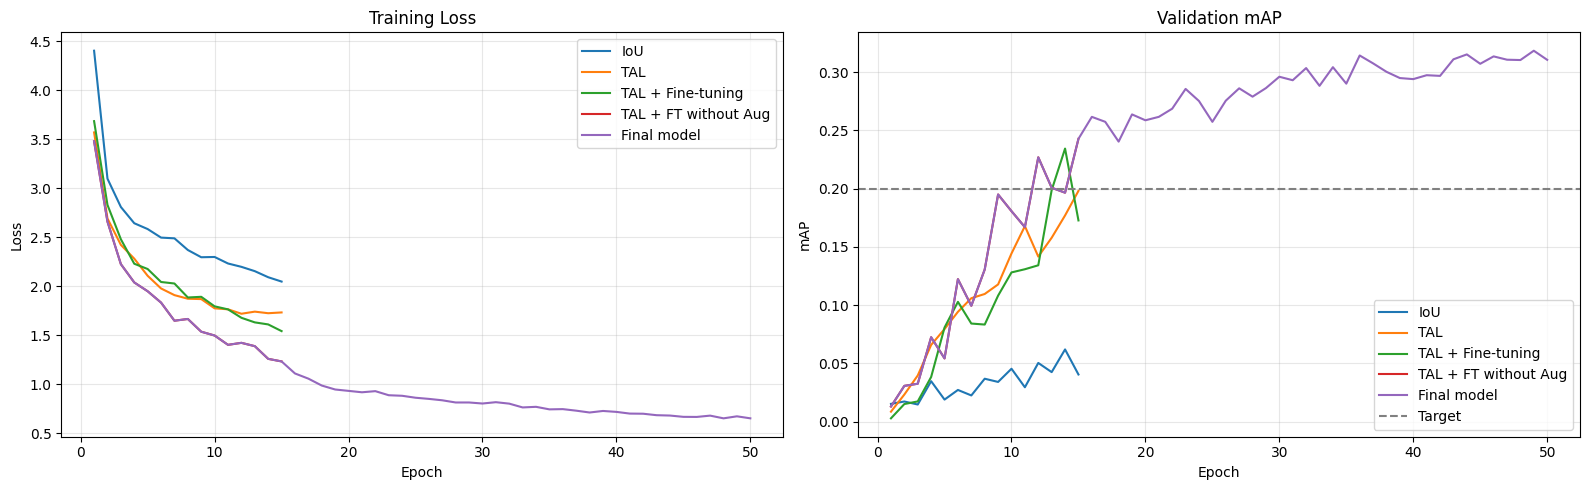

In [31]:
import matplotlib.pyplot as plt

experiments = {
    "IoU": history_baseline,
    "TAL": history_tal,
    "TAL + Fine-tuning": history_tal_finetune,
    "TAL + FT without Aug": history_no_aug,
    "Final model": history_final
}

results = pd.DataFrame([
    {
        "Experiment": name,
        "Epochs": len(history),
        "Best epoch": history.loc[history["val_map"].idxmax(), "epoch"],
        "Best Val mAP": history["val_map"].max(),
        "Final Loss": history["train_loss"].iloc[-1]
    }
    for name, history in experiments.items()
])

display(results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for name, history in experiments.items():
    axes[0].plot(history["epoch"], history["train_loss"], label=name)
    axes[1].plot(history["epoch"], history["val_map"], label=name)

axes[0].set_title("Training Loss")
axes[0].set_ylabel("Loss")

axes[1].set_title("Validation mAP")
axes[1].set_ylabel("mAP")
axes[1].axhline(0.2, linestyle="--", color="gray", label="Target")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/training_curves.png", dpi=200)
plt.show()

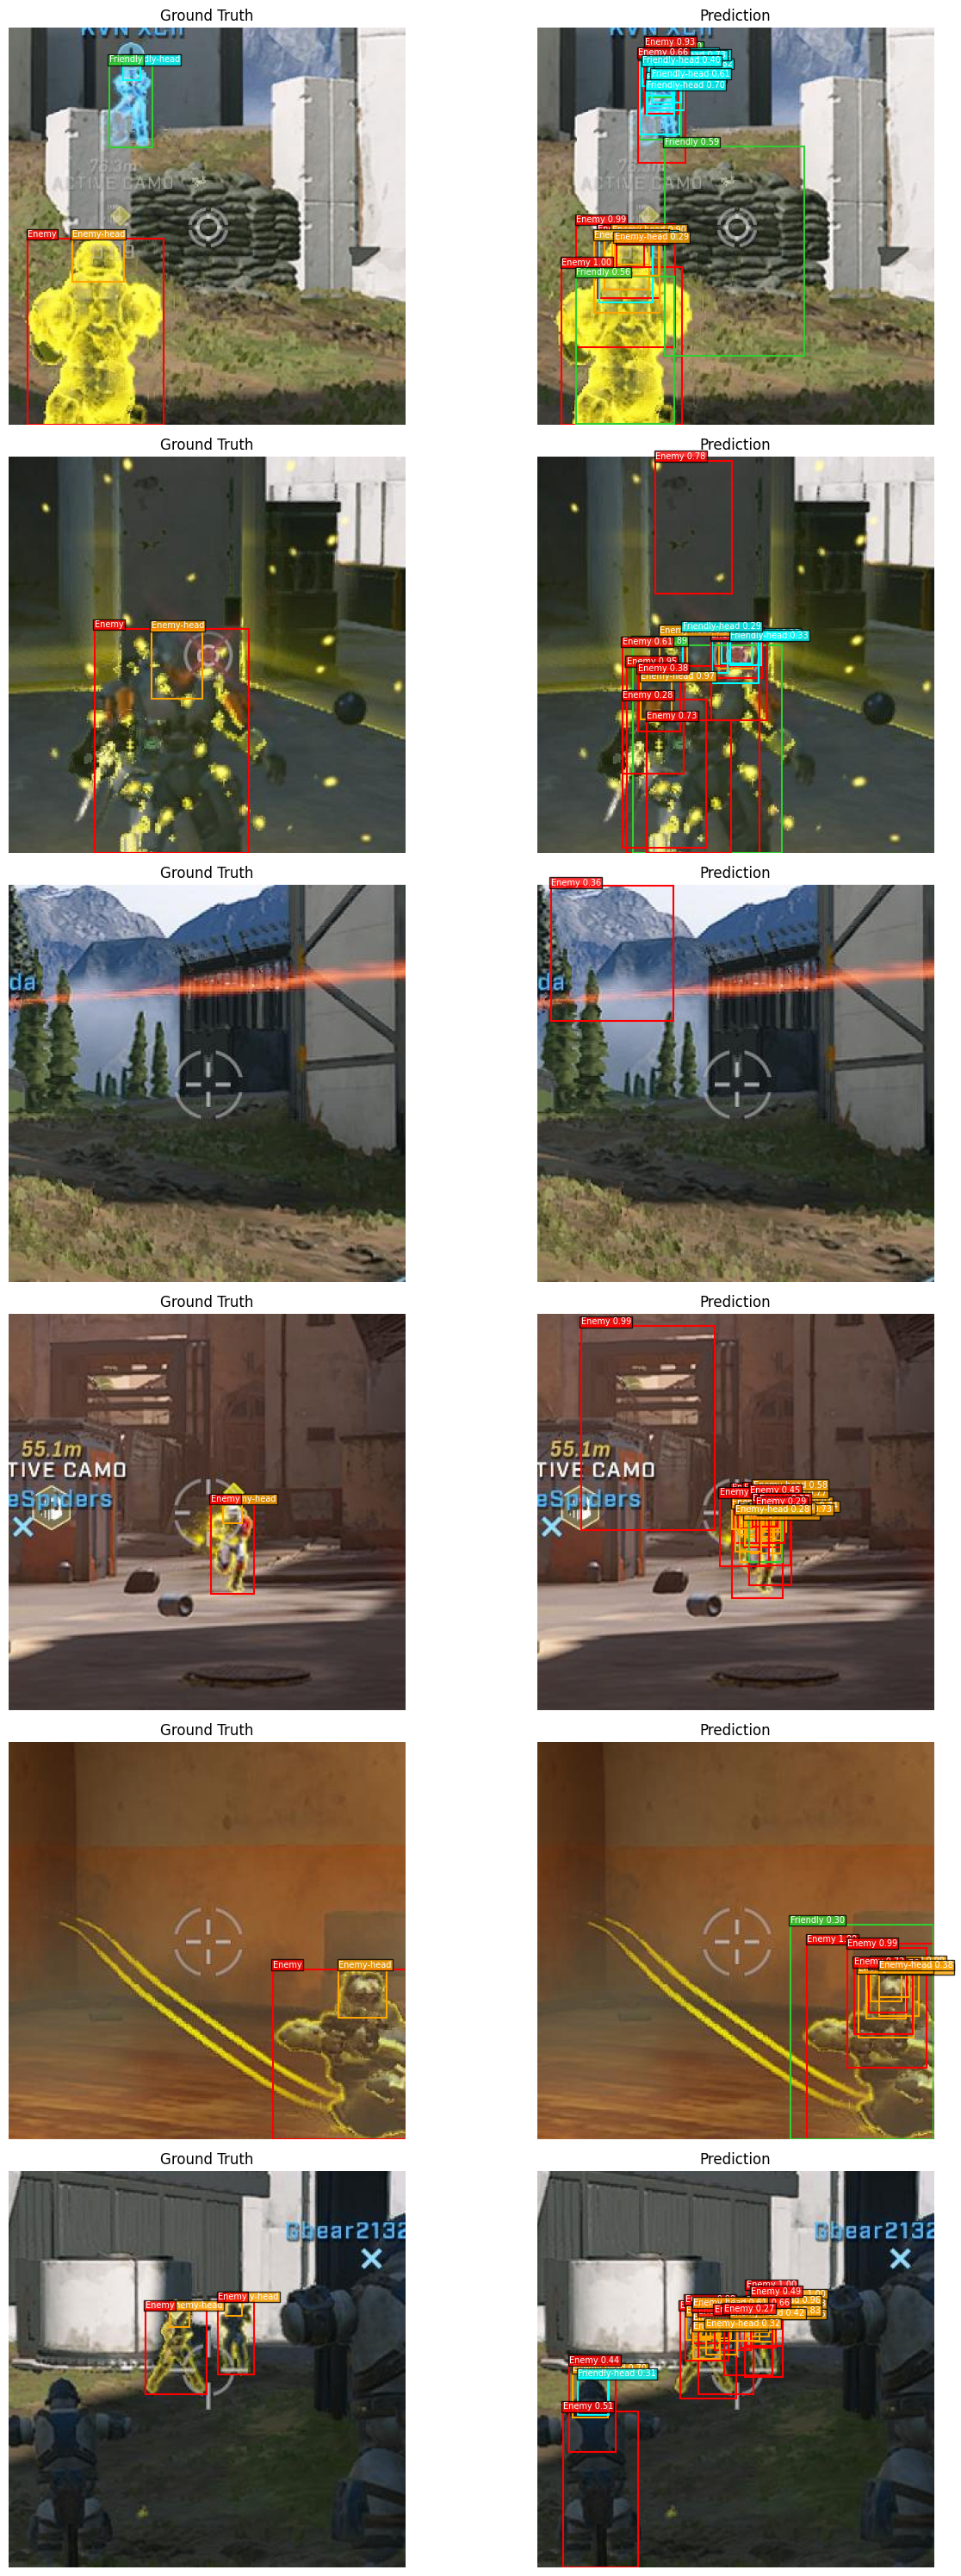

In [32]:
import matplotlib.patches as patches

CLASS_NAMES = [
    "Enemy", "Enemy-head",
    "Friendly", "Friendly-head"
]

COLORS = ["red", "orange", "limegreen", "cyan"]


def draw_boxes(ax, image, boxes, labels, scores=None):
    ax.imshow(image)
    ax.axis("off")

    for i, (box, label) in enumerate(zip(boxes, labels)):
        x1, y1, x2, y2 = box.tolist()
        label = int(label)
        color = COLORS[label]

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=1.5,
            edgecolor=color,
            facecolor="none"
        )

        ax.add_patch(rect)

        text = CLASS_NAMES[label]

        if scores is not None:
            text += f" {scores[i]:.2f}"

        ax.text(
            x1, max(0, y1 - 3), text,
            color="white",
            fontsize=7,
            bbox=dict(facecolor=color, alpha=0.8, pad=1)
        )


model.eval()

images, targets = next(iter(test_loader))

with torch.no_grad():
    predictions = filter_predictions(
        model(images.to(device)),
        score_threshold=0.25,
        nms_threshold=0.5
    )

fig, axes = plt.subplots(6, 2, figsize=(14, 30))

for i in range(6):
    image = images[i].permute(1, 2, 0).cpu().numpy()
    image = np.clip(
        image * np.array(std) + np.array(mean),
        0, 1
    )

    gt_boxes = box_convert(
        targets[i]["boxes"], "xywh", "xyxy"
    )

    draw_boxes(
        axes[i, 0], image,
        gt_boxes, targets[i]["labels"]
    )

    draw_boxes(
        axes[i, 1], image,
        predictions[i]["boxes"],
        predictions[i]["labels"],
        predictions[i]["scores"]
    )

    axes[i, 0].set_title("Ground Truth")
    axes[i, 1].set_title("Prediction")

plt.tight_layout()
plt.savefig(
    "/kaggle/working/detection_examples.png",
    dpi=150
)
plt.show()

## Результаты экспериментов и выводы

Для решения задачи Object Detection была реализована архитектура детектора на основе EfficientNet-B0, FPN и Decoupled Head. В качестве функции потерь для локализации объектов использовалась DIoU Loss.

### Результаты экспериментов

| Эксперимент | Эпохи | Best Validation mAP |
|---|---:|---:|
| IoU Assignment | 15 | 0.0619 |
| TAL Assignment | 15 | 0.1980 |
| TAL + Fine-tuning | 15 | 0.2343 |
| TAL + Fine-tuning без аугментаций | 15 | 0.2427 |
| Финальное обучение | 50 | 0.3183 |

### 1. Какой алгоритм назначения таргетов показал себя лучше и почему?

Наилучший результат показал Task-Aligned Assigner (TAL). При переходе от IoU Assignment к TAL значение Validation mAP увеличилось с 0.0619 до 0.1980.

В отличие от статического назначения таргетов на основе IoU исходных якорей, TAL учитывает качество текущих предсказаний модели, объединяя информацию о классификации и локализации объектов. Это позволяет динамически выбирать положительные примеры в процессе обучения.

### 2. Какое улучшение принесло наибольший прирост качества и почему?

Наибольший наблюдаемый прирост обеспечило внедрение TAL — абсолютное увеличение mAP составило 0.1361.

Частичная разморозка Backbone также улучшила результат, увеличив mAP до 0.2343. Это позволило адаптировать предобученные признаки EfficientNet-B0 к особенностям изображений из игры Halo Infinite.

Продолжение обучения со сниженным learning rate позволило достичь Validation mAP 0.3183.

### 3. Какое улучшение не привело к существенному изменению метрики и почему?

Использованные аугментации не продемонстрировали положительного влияния на итоговую метрику. После их отключения Validation mAP увеличился с 0.2343 до 0.2427.

Возможная причина заключается в том, что цветовые характеристики персонажей важны для различения союзников и противников, а цветовые преобразования могут искажать эти признаки.

Однако разница между результатами невелика. Поскольку для каждой конфигурации был проведён один запуск, нельзя исключить влияние случайной инициализации и порядка обучающих примеров.

### Анализ визуальных предсказаний

Модель успешно обнаруживает персонажей различных размеров и их головы. Вместе с тем наблюдаются дублирующиеся Bounding Box, ошибки классификации и ложные срабатывания на фоновых объектах.

Возможные направления дальнейшего улучшения:

- настройка алгоритма NMS;
- подбор размеров и пропорций якорей;
- подбор параметров TAL;
- исследование отдельных видов аугментаций.

### Финальный результат

- Best Validation mAP 0.50:0.95: **0.3183**
- Test mAP 0.50:0.95: **0.3033**
- Целевой Test mAP: **0.2000**

Целевое значение метрики превышено на 51.65%. Таким образом, поставленная задача успешно выполнена.